In [ ]:
# packages
import os
import numpy as np
import pandas as pd
import seaborn as sns
import pickle   
from matplotlib import pyplot as plt
import statsmodels.formula.api as smf
from scipy.special import logit
from scipy.stats import zscore
from scipy.stats import pearsonr
import scripts.plotting_functions as plt_func
import scripts.helper_functions as func

# what data set are we analysing
dataset = 'patient'

# paths
raw_path = '~/code/ast_human/data/raw/' + dataset + '/'
clean_path = '~/code/ast_human/data/clean/' + dataset + '/'
datalist_path = '~/code/ast_human/data/datalists/' + dataset + '/'

# make plotting dir
p = os.path.expanduser('~/code/ast_human/figures/') + dataset
os.makedirs(p, exist_ok=True)

# read data
data = pd.read_csv(clean_path + 'clean_data.csv')

/home/rowan/code/ast_human/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# make sure data has stage names and condition labels before passing
stage_order = ['SD', 'CD', 'IDS1', 'IDS2', 'IDS3', 'IDS4', 'EDS', 'EDSR']

data['stage'] = data['stage'].replace({
    0.0: 'SD',
    1.0: 'CD',
    2.0: 'IDS1',
    3.0: 'IDS2',
    4.0: 'IDS3',
    5.0: 'IDS4',
    6.0: 'EDS',
    7.0: 'EDSR'
})

# make sure its ordered correctly
data['stage'] = pd.Categorical(
    data['stage'],
    categories=stage_order,
    ordered=True
)

# add condition column
data['condition'] = 'patient'

In [3]:
traj_df, tmp_df = func.calc_behavioural_metrics(data)

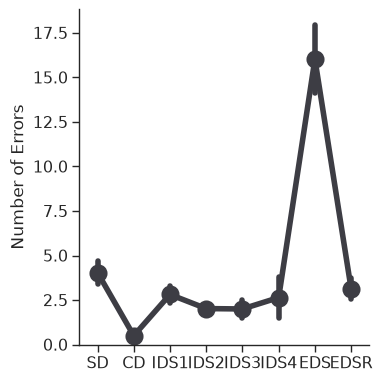

In [4]:
plt_func.plot_trajectories(df=traj_df, stage='stage', condition='condition')

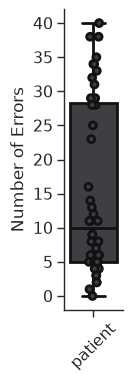

In [5]:
plt_func.plot_costs(df=tmp_df, costs='shift_cost', condition='condition')

In [6]:
means, results = func.get_p_switch_after_correct(data, n_choices=5)

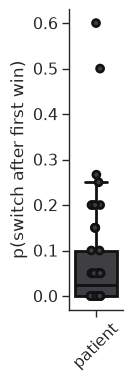

In [7]:
means['condition'] = 'patient'
plt_func.plot_switch(df=means,p_switch='p_switch',condition='condition')